# 4 · When the attacker knows the physics

The noncentrality law $\lambda(s) = (1-s)^2 \lambda(0)$ and the snapshot monitor along the stealth dial,
closed form against simulation. See [Lesson 4](../docs/lessons/04-when-the-attacker-knows-the-physics.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from fdicps import plotting
from fdicps.dual_anomaly_data_generation.parameters import load_sensor_parameters

plotting.use_style()
P = load_sensor_parameters()

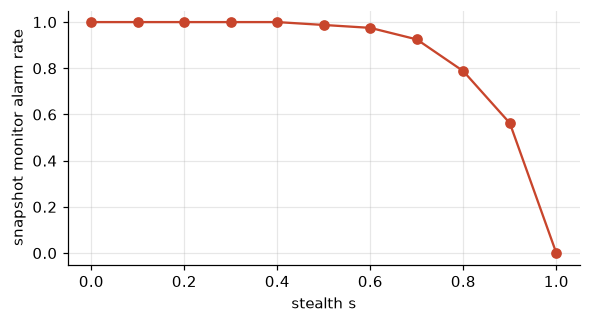

In [2]:
from fdicps.adversarial_robustness_analysis.attacks import consistency_variant
from fdicps.adversarial_robustness_analysis.monitors import snapshot_alarm

grid = np.linspace(0, 1, 11)
seeds = range(3_000_000, 3_000_080)
measured = [snapshot_alarm(np.stack([consistency_variant(s, "offset", x).values for s in seeds]), P).mean() for x in grid]
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(grid, measured, "o-", color=plotting.FDI_COLOR)
ax.set(xlabel="stealth s", ylabel="snapshot monitor alarm rate");

In [3]:
from fdicps.cross_sensor_consistency_model.navigation import snapshot_models

idx, wls = snapshot_models(P)[1]
a_one = np.array([100.0, 0, 0, 0, 0])
a_all = wls.H @ np.array([100.0, 0.0])
for s in (0.0, 0.5, 0.9, 1.0):
    lam = float(wls.noncentrality(s * a_all + (1 - s) * a_one))
    print(f"s = {s:.1f}: lambda = {lam:7.2f} = {(1 - s) ** 2:.2f} x lambda(0)")

s = 0.0: lambda =  196.01 = 1.00 x lambda(0)
s = 0.5: lambda =   49.00 = 0.25 x lambda(0)
s = 0.9: lambda =    1.96 = 0.01 x lambda(0)
s = 1.0: lambda =    0.00 = 0.00 x lambda(0)
